<center><h1>Liang_Qian_HW3</h1></center>
<br>
<br>

Name: Qian Liang
<br>
Github Username: qliang21-77
<br>
USC ID: 9681620075

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [5]:
import glob
import os
import numpy as np
import pandas as pd
from pathlib import Path

from matplotlib import pyplot as plt
from scipy.stats import bootstrap

Get the AReM Data Set

In [6]:
folder_name = ['bending1','bending2','cycling','lying','sitting','standing','walking']

bending1_files=[]
bending2_files=[]
cycling_files=[]
lying_files=[]
sitting_files=[]
standing_files=[]
walking_files=[]

for names in folder_name:
    if names == 'bending1':
        path = 'AReM/'+names+'/*.csv'
        bending1_files = glob.glob(path)
    if names == 'bending2':
        path = 'AReM/'+names+'/*.csv'
        bending2_files = glob.glob(path)
    if names == 'bending2':
        path = 'AReM/'+names+'/*.csv'
        bending2_files = glob.glob(path)
    if names == 'cycling':
        path = 'AReM/'+names+'/*.csv'
        cycling_files = glob.glob(path)
    if names == 'lying':
        path = 'AReM/'+names+'/*.csv'
        lying_files = glob.glob(path)
    if names == 'sitting':
        path = 'AReM/'+names+'/*.csv'
        sitting_files = glob.glob(path)
    if names == 'standing':
        path = 'AReM/'+names+'/*.csv'
        standing_files = glob.glob(path)
    if names == 'walking':
        path = 'AReM/'+names+'/*.csv'
        walking_files = glob.glob(path)


### (b) Test and Train Data

In [7]:
import re

def get_num(file):
    return int(re.search(r'dataset(\d+)', file).group(1))

for files in [bending1_files, bending2_files, cycling_files,
              lying_files, sitting_files, standing_files, walking_files]:
    files.sort(key=get_num)


test_data = (
    bending1_files[:2] +
    bending2_files[:2] +
    cycling_files[:3] +
    lying_files[:3] +
    sitting_files[:3] +
    standing_files[:3] +
    walking_files[:3]
)
train_data=(
    bending1_files[2:] +
    bending2_files[2:] +
    cycling_files[3:] +
    lying_files[3:] +
    sitting_files[3:] +
    standing_files[3:] +
    walking_files[3:]    
)
columns = [
    'time', 'avg_rss12', 'var_rss12',
    'avg_rss13', 'var_rss13',
    'avg_rss23', 'var_rss23'
]
test_df = []
for file in test_data:
    df = pd.read_csv(file, skiprows=4)
    df.columns = columns
    df['Dataset'] = os.path.basename(file)
    df['Label'] = os.path.basename(os.path.dirname(file))
    test_df.append(df)
test_df = pd.concat(test_df, ignore_index=True)

train_df = []
for file in train_data:
    df = pd.read_csv(file, skiprows=4)
    df.columns = columns
    df['Dataset'] = os.path.basename(file)
    df['Label'] = os.path.basename(os.path.dirname(file))
    train_df.append(df)

train_df = pd.concat(train_df, ignore_index=True)
train_df

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,Dataset,Label
0,0,42.00,0.71,21.25,0.43,30.00,0.00,dataset3.csv,bending1
1,250,41.50,0.50,20.25,1.48,31.25,1.09,dataset3.csv,bending1
2,500,41.50,0.50,14.25,1.92,33.00,0.00,dataset3.csv,bending1
3,750,40.75,0.83,15.75,0.43,33.00,0.00,dataset3.csv,bending1
4,1000,40.00,0.71,20.00,2.74,32.75,0.43,dataset3.csv,bending1
...,...,...,...,...,...,...,...,...,...
33114,118750,34.50,6.18,9.00,3.56,12.67,4.19,dataset15.csv,walking
33115,119000,25.75,6.02,13.75,2.05,16.00,1.58,dataset15.csv,walking
33116,119250,31.50,3.35,10.25,5.12,16.25,2.95,dataset15.csv,walking
33117,119500,33.75,2.77,14.00,3.24,13.75,0.43,dataset15.csv,walking


### (c) Feature Extraction

#### i. Research

## Q: Research what types of time-domain features are usually used in time series classification and list them (examples are minimum, maximum, mean, etc).
## Answer：
### Basic Descriptive Statistics:
- Mean: average of the time series
- Median: middle value
- Minimum and Maximum: lowest and highest values
- Range: difference between maximum and minimum values
### Dispersal Variability
- Variance and Standard deviation: diffference form the mean
- Interquartile Range: range from q3-q1
- Root Mean Square: 
- Normative Deviation
### Distribution Shape
- Skewness: asymmetry of data distribution around its mean
- Kurtosis: outliers in the data distribution
- Quantiles / Percentiles: division of point representing data distribution
### Correlation 
- Autocorrelation: linear dependence
- Cross-correlation: similarity between two different time series

#### ii. Extraction

In [8]:
all_data = pd.concat([test_df, train_df], ignore_index=True)
features=[]
for (label,dataset),df in all_data.groupby(['Label','Dataset'],sort=False):
    stats = df.iloc[:,1:7].describe().drop('count')
    stats = stats.loc[['min', 'max', 'mean', '50%', 'std', '25%', '75%']]
    row = [label, dataset] + stats.T.to_numpy().flatten().tolist()
    features.append(row)

features_df = pd.DataFrame(features)
names = ['min', 'max', 'mean', 'median', 'std', 'Q1_', 'Q3_']

features_df.columns = ['Label', 'Dataset'] + [
    f'{name}{i}' for i in range(1, 7) for name in names
]

features_df = features_df.sort_values(
    by='Label',
    ascending=True
).reset_index(drop=True)

features_df.insert(0, 'Instances', range(1, len(features_df) + 1))

features_df




,Instances,Label,Dataset,min1,max1,mean1,median1,std1,Q1_1,Q3_1,...,std5,Q1_5,Q3_5,min6,max6,mean6,median6,std6,Q1_6,Q3_6
0,1,bending1,dataset1.csv,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,2,bending1,dataset2.csv,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,3,bending1,dataset3.csv,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,4,bending1,dataset4.csv,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,5,bending1,dataset5.csv,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,walking,dataset11.csv,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,85,walking,dataset12.csv,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
85,86,walking,dataset13.csv,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,87,walking,dataset14.csv,23.50,46.25,34.873229,35.25,4.531720,31.75,38.2500,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


#### iii. Standard Deviation Estimate the standard deviation of each of the time-domain features you
extracted from the data. Then, use Python's bootstrapped or any other
method to build a 90% bootsrap condence interval for the standard deviation
of each feature.

In [9]:
features_df_std = features_df.iloc[:,3:].std()

features_df_std 

min1       9.569975
max1       4.394362
mean1      5.335718
median1    5.440054
std1       1.772153
Q1_1       6.153590
Q3_1       5.138925
min2       0.000000
max2       5.062729
mean2      1.574164
median2    1.412244
std2       0.884105
Q1_2       0.946386
Q3_2       2.125266
min3       2.956462
max3       4.875137
mean3      4.008380
median3    4.036396
std3       0.946710
Q1_3       4.220658
Q3_3       4.171628
min4       0.000000
max4       2.183625
mean4      1.166114
median4    1.145586
std4       0.458242
Q1_4       0.843620
Q3_4       1.552504
min5       6.124001
max5       5.741238
mean5      5.675593
median5    5.813782
std5       1.024898
Q1_5       6.096465
Q3_5       5.531720
min6       0.045838
max6       2.518921
mean6      1.154812
median6    1.086474
std6       0.517617
Q1_6       0.758584
Q3_6       1.523599
dtype: float64

In [10]:
# bootstrap
confidence_level = 0.9
data= features_df.iloc[:,3:]
CI=[]
for i in data:
    result= bootstrap(
        (data[i].to_numpy(),),
        np.std, 
        confidence_level=confidence_level,method='basic'   
    )
    CI.append([i,result.confidence_interval.low,result.confidence_interval.high])
CI_df = pd.DataFrame(CI, columns=['Stats', 'Lower', 'Upper'])
CI_df


,Stats,Lower,Upper
0,min1,8.305109,10.801811
1,max1,3.476893,5.417795
2,mean1,4.752725,5.930024
3,median1,4.862841,6.044500
4,std1,1.586221,1.966120
5,Q1_1,5.616851,6.693201
6,Q3_1,4.408167,5.896739
7,min2,0.000000,0.000000
8,max2,4.686013,5.468543
9,mean2,1.434746,1.745449


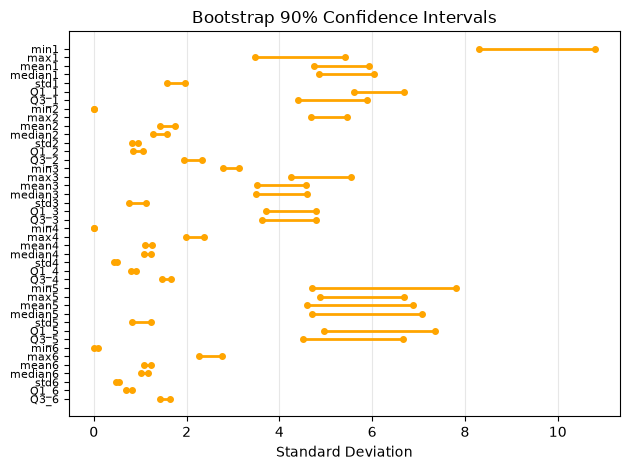

<Figure size 1200x1800 with 0 Axes>

In [11]:
for i in range(len(CI_df)):
    plt.plot(
        [CI_df['Lower'][i], CI_df['Upper'][i]],
        [i, i],
        'o-',
        color='orange',
        linewidth=2,
        markersize=4
    )

plt.yticks(range(len(CI_df)), CI_df['Stats'],fontsize=8)
plt.gca().invert_yaxis()
plt.xlabel("Standard Deviation")
plt.title("Bootstrap 90% Confidence Intervals")
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.figure(figsize=(12, 18))
plt.show()

#### iv. Select Features

median, mean,Quartiles are good ways of distingushing the calsses because these three stats have smaller confidence interval meaning when different
sample is applied to the model, the standard deviation or changes are relatively smaller and more accurate

## 2. ISLR 3.7.4

I collect a set of data (n = 100 observations) containing a single
predictor and a quantitative response. I then fit a linear regression
model to the data, as well as a separate cubic regression, i.e. Y =
β0 + β1X + β2X^2 + β3X^3 + ϵ.

### 
(a) Linear Train

Q: Suppose that the true relationship between X and Y is linear,
i.e. Y = β0 + β1X + ϵ. Consider the training residual sum of
squares (RSS) for the linear regression, and also the training
RSS for the cubic regression. Would we expect one to be lower
than the other, would we expect them to be the same, or is there
not enough information to tell? Justify your answer.


A: expect RSS for cubic regression lower than other, because cubic regression fits more complex data with more flexibility

### (b) Linear Test

Q: Answer (a) using test rather than training RSS.


Test RSS for cubic regression would be higher as relationshit bewteen x and y is a linear model with lower variance, but cubic regression fit more flexible model to consider the noise causing overfitting.

### (c) Not Linear Train

Q: Suppose that the true relationship between X and Y is not linear,
but we don’t know how far it is from linear. Consider the training
RSS for the linear regression, and also the training RSS for the
cubic regression. Would we expect one to be lower than the
other, would we expect them to be the same, or is there not
enough information to tell? Justify your answer.


A: expect RSS for cubic regression lower than other, since the relationship is not linear,
cubic regression fits more flexible model

### (d) Not Linear Testing

Q: Answer (c) using test rather than training RSS.

A: We cannot tell based on the given information - we need to know the relationship better whther the relationship is slightly non-linear
or highly cubic. If highly cubic, we need to understand the variance and bias to determine the TEST RSS.

## 3. ISLR 3.7.3 - Extra Practice 

## 3. ISLR 3.7.5 - Extra Practice 